# Length cutoff analysis

Reads the latest `python -m length_analysis --mode deletion` run over the 1,074-candidate short
list and plots the Figure 4 length-variation panels.

`k = round(p * L)` residues are removed from one terminus, **half-up**, for p = 0.05, 0.1, 0.2.
Each (parent, terminus, p) cell is a single deterministic truncation, folded on its own — there
is no replicate axis and no `sd_` column, unlike the mutation sweep. Cells with `k == 0` are
skipped by the runner, so the shortest peptides have no p = 0.05 row.

Inputs (CSV file contracts, no module imports):

- `length_deletion_curves.csv` — one row per (parent, terminus, p): the truncated variant's score
- `length_deletion_robustness.csv` — one row per (parent, terminus): parent baseline and collapse

Two model outputs are used throughout, named as in `mutation_analysis.ipynb`:

- **σ (sigma score)** — the **raw logit difference**, `logit_AMP − logit_nonAMP`, straight from the
  GNN head. Unbounded, signed; σ > 0 is an AMP call.
- **P(AMP)** — the **temperature-scaled probability**, `sigmoid(σ / T)`, so P ≥ 0.5 and σ > 0
  select exactly the same peptides.

Δ is taken as **truncated − original**, so peptides that tolerate truncation sit near 0 and
fragile ones go negative. This matches `mutation_analysis.ipynb` and the axis of the spec's
example plot; the spec's prose writes `Original − Mutant`, which is the same quantity negated.

In [1]:
from __future__ import annotations

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


def find_repo_root() -> Path:
    here = Path.cwd().resolve()
    for path in (here, *here.parents):
        if (path / "length_analysis").is_dir():
            return path
    raise FileNotFoundError("Could not locate the repository root.")


def latest_run_csv(data_root: Path, filename: str) -> Path:
    results_root = data_root / "results"
    candidates = list((results_root / "runs").glob(f"*/{filename}"))
    if not candidates:
        return results_root / filename
    return max(candidates, key=lambda path: path.stat().st_mtime_ns)


ROOT = find_repo_root()
DATA_ROOT = ROOT / "data" / "proteomes" / "1k_confirmed_candidates"
CURVES_CSV = latest_run_csv(DATA_ROOT, "length_deletion_curves.csv")
ROBUSTNESS_CSV = latest_run_csv(DATA_ROOT, "length_deletion_robustness.csv")

TERMINUS_ORDER = ["N", "C"]
TERMINUS_LABEL = {"N": "N-terminal deletion", "C": "C-terminal deletion"}
TERMINUS_COLOR = {"N": "#2a78d6", "C": "#eb6834"}
TERMINUS_MARKER = {"N": "o", "C": "s"}
TERMINUS_CMAP = {"N": "Blues", "C": "Oranges"}

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["font.family"] = "monospace"
# TrueType (Type 42) so PDF text stays editable vectors instead of raster outlines.
plt.rcParams["pdf.fonttype"] = 42

SPINE_COLOR = "#2b2b2b"
LABEL_SIZE = 10.5
TITLE_SIZE = 12


def style_axes(ax, grid_axis: str = "y") -> None:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(SPINE_COLOR)
        ax.spines[side].set_linewidth(0.8)
    ax.grid(False)
    ax.grid(axis=grid_axis, linestyle="--", linewidth=0.6, alpha=0.5, zorder=0)
    ax.set_axisbelow(True)
    ax.tick_params(axis="both", labelsize=8.5, length=3.5, width=0.8, colors=SPINE_COLOR)


print("Curves:     ", CURVES_CSV)
print("Robustness: ", ROBUSTNESS_CSV)

Curves:      /mnt/c/Users/bioin/Documents/Peptide-Anti-microbial-Properties-Prediction/data/proteomes/1k_confirmed_candidates/results/runs/2026-11-06_01-46/length_deletion_curves.csv
Robustness:  /mnt/c/Users/bioin/Documents/Peptide-Anti-microbial-Properties-Prediction/data/proteomes/1k_confirmed_candidates/results/runs/2026-11-06_01-46/length_deletion_robustness.csv


In [2]:
curves = pd.read_csv(CURVES_CSV)
robustness = pd.read_csv(ROBUSTNESS_CSV)

# Project vocabulary is sigma, not margin. The source CSVs still carry the
# margin_* / logit_margin names written by length_analysis.
SIGMA_RENAMES = {
    "parent_logit_margin": "parent_sigma",
    "margin_auc": "deletion_sigma_auc",
    "margin_slope": "sigma_slope",
    "logit_margin": "sigma",
    "delta_logit_margin": "delta_sigma",
}
curves = curves.rename(columns=SIGMA_RENAMES)
robustness = robustness.rename(columns=SIGMA_RENAMES)

PARENT_COLUMNS = ["parent_id", "length", "parent_pred", "parent_prob_AMP", "parent_sigma"]
parents = robustness[PARENT_COLUMNS].drop_duplicates("parent_id")

curves = curves.merge(parents, on="parent_id", how="left")
curves["called_AMP"] = (curves["sigma"] > 0).astype(float)

# Figures restrict to candidates the model already calls AMP: sigma > 0.
amp_parents = parents[parents["parent_sigma"] > 0]
amp_curves = curves[curves["parent_id"].isin(amp_parents["parent_id"])]

P_LEVELS = sorted(curves["p"].unique())

print(f"parents:    {len(parents):,}   sigma > 0: {len(amp_parents):,}")
print(f"curve rows: {len(curves):,}   AMP-only: {len(amp_curves):,}")
print(f"p levels:   {P_LEVELS}")
print(f"termini:    {sorted(curves['terminus'].unique())}")
# k == 0 cells are dropped by the runner, so cell counts fall at the smallest p.
print(curves.groupby(["terminus", "p"]).size().rename("cells"))
robustness.head()

parents:    1,074   sigma > 0: 578
curve rows: 6,426   AMP-only: 3,458
p levels:   [np.float64(0.05), np.float64(0.1), np.float64(0.2)]
termini:    ['C', 'N']
terminus  p   
C         0.05    1065
          0.10    1074
          0.20    1074
N         0.05    1065
          0.10    1074
          0.20    1074
Name: cells, dtype: int64


,run_id,parent_id,terminus,sequence,length,parent_pred,parent_prob_AMP,parent_sigma,n_variants,n_p_levels,mean_k,retention,retention_first_p,retention_last_p,mean_prob_AMP,mean_delta_prob_AMP,deletion_sigma_auc,sigma_slope,gene_names,leading_razor_protein
0,2026-11-06_01-46,SEQ_1,C,LSLVTKKKRFWCWQRPKYQFL,21,0,0.344183,-0.493699,3,3,2.333333,0.333333,0,1,0.442527,0.098344,-0.158804,2.987828,DFNA5,O60443
1,2026-11-06_01-46,SEQ_1,N,LSLVTKKKRFWCWQRPKYQFL,21,0,0.344183,-0.493699,3,3,2.333333,0.666667,1,1,0.608378,0.264195,0.306450,4.092269,DFNA5,O60443
2,2026-11-06_01-46,SEQ_2,C,RMFRGSLYKRYPSLWRRL,18,1,0.978130,2.910319,3,3,2.333333,1.000000,1,1,0.902608,-0.075521,1.657967,-6.759468,SMARCB1,Q12824
3,2026-11-06_01-46,SEQ_2,N,RMFRGSLYKRYPSLWRRL,18,1,0.978130,2.910319,3,3,2.333333,1.000000,1,1,0.963352,-0.014778,3.115719,0.628619,SMARCB1,Q12824
4,2026-11-06_01-46,SEQ_3,C,SLVTKKKRFWCWQRPKYQFL,20,1,0.589915,0.278444,3,3,2.333333,0.666667,0,1,0.504169,-0.085745,0.062371,1.823624,DFNA5,O60443


## Figure 4 — number of AMP candidates as a function of Δ and p

One panel per terminus. The x-axis is Δ, the y-axis is the deletion level p, and the colour is the
number of AMP candidates falling in that cell. Rows are drawn at equal height, so the three p
levels read as categories rather than as a 0.05–0.2 axis.

Only the σ > 0 parents are counted, the same population as the curves below. Bin edges are
symmetric about 0 at the 99th percentile of |Δ|, and the tails are clipped into the end bins so
no peptide is dropped from the counts.

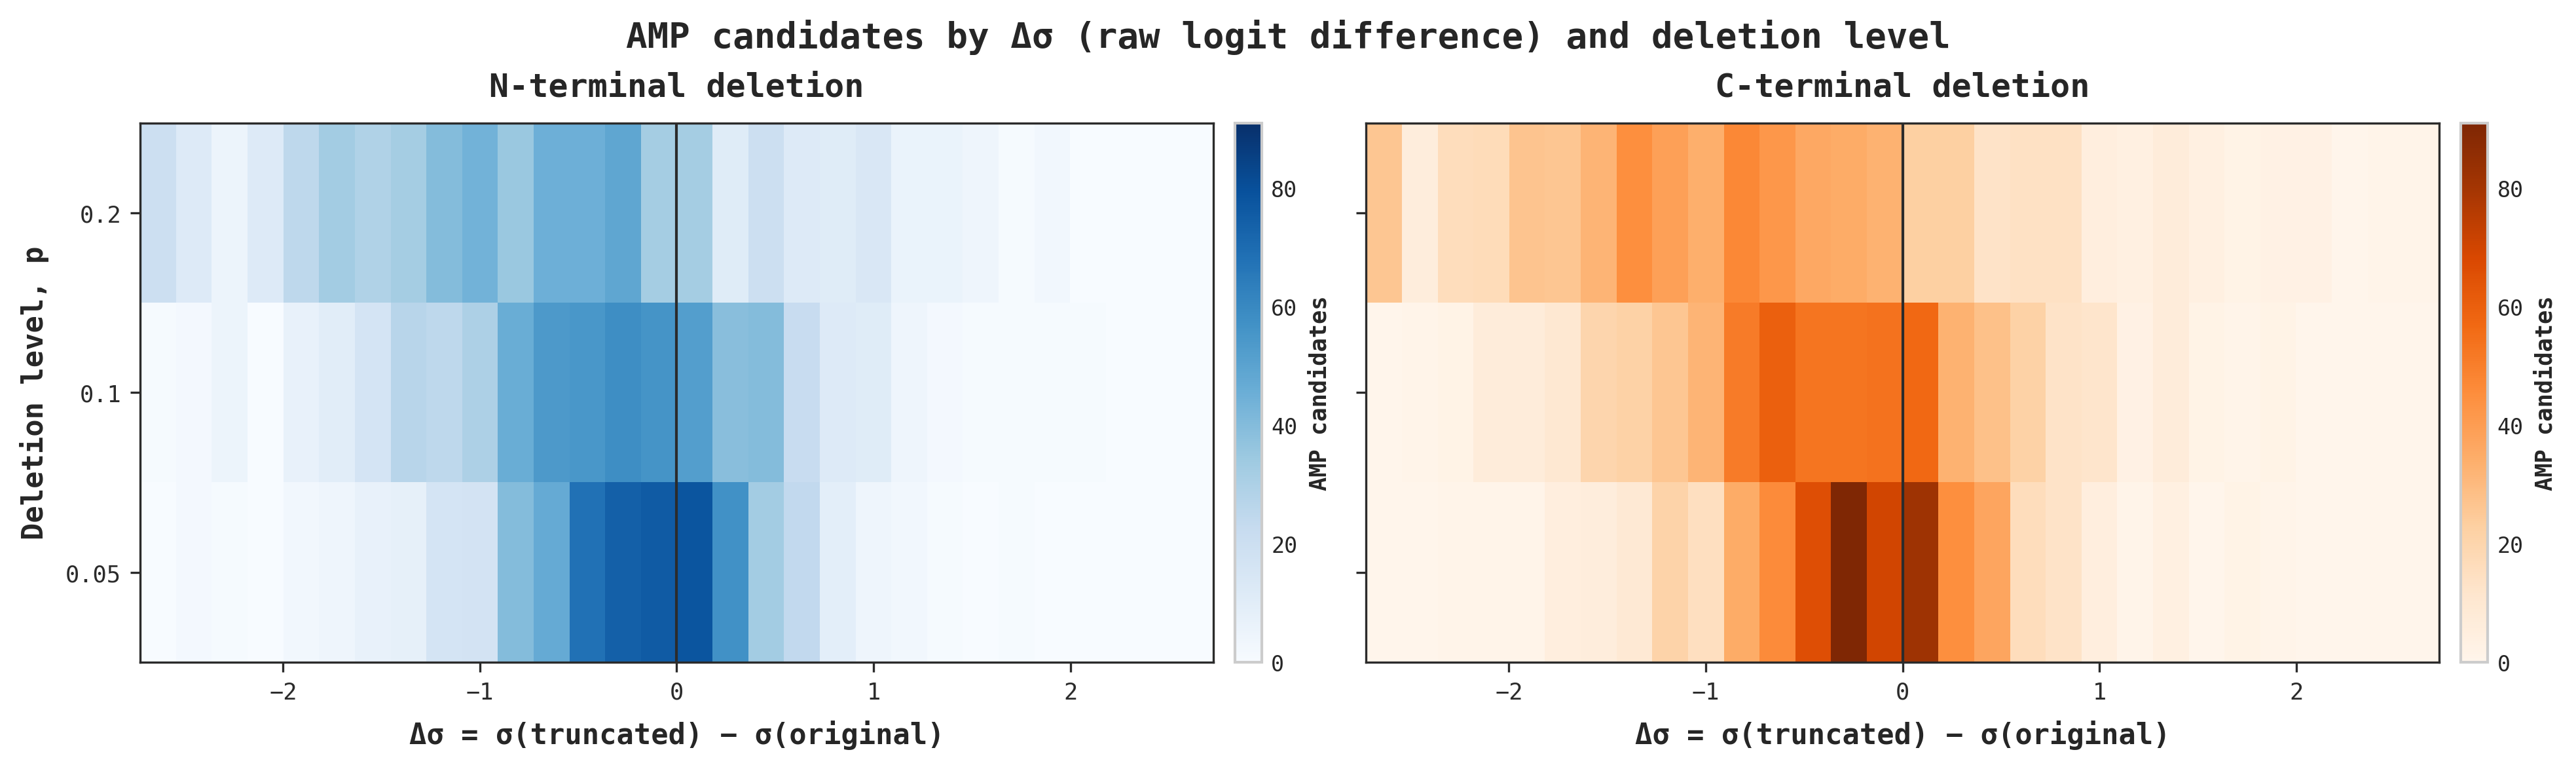

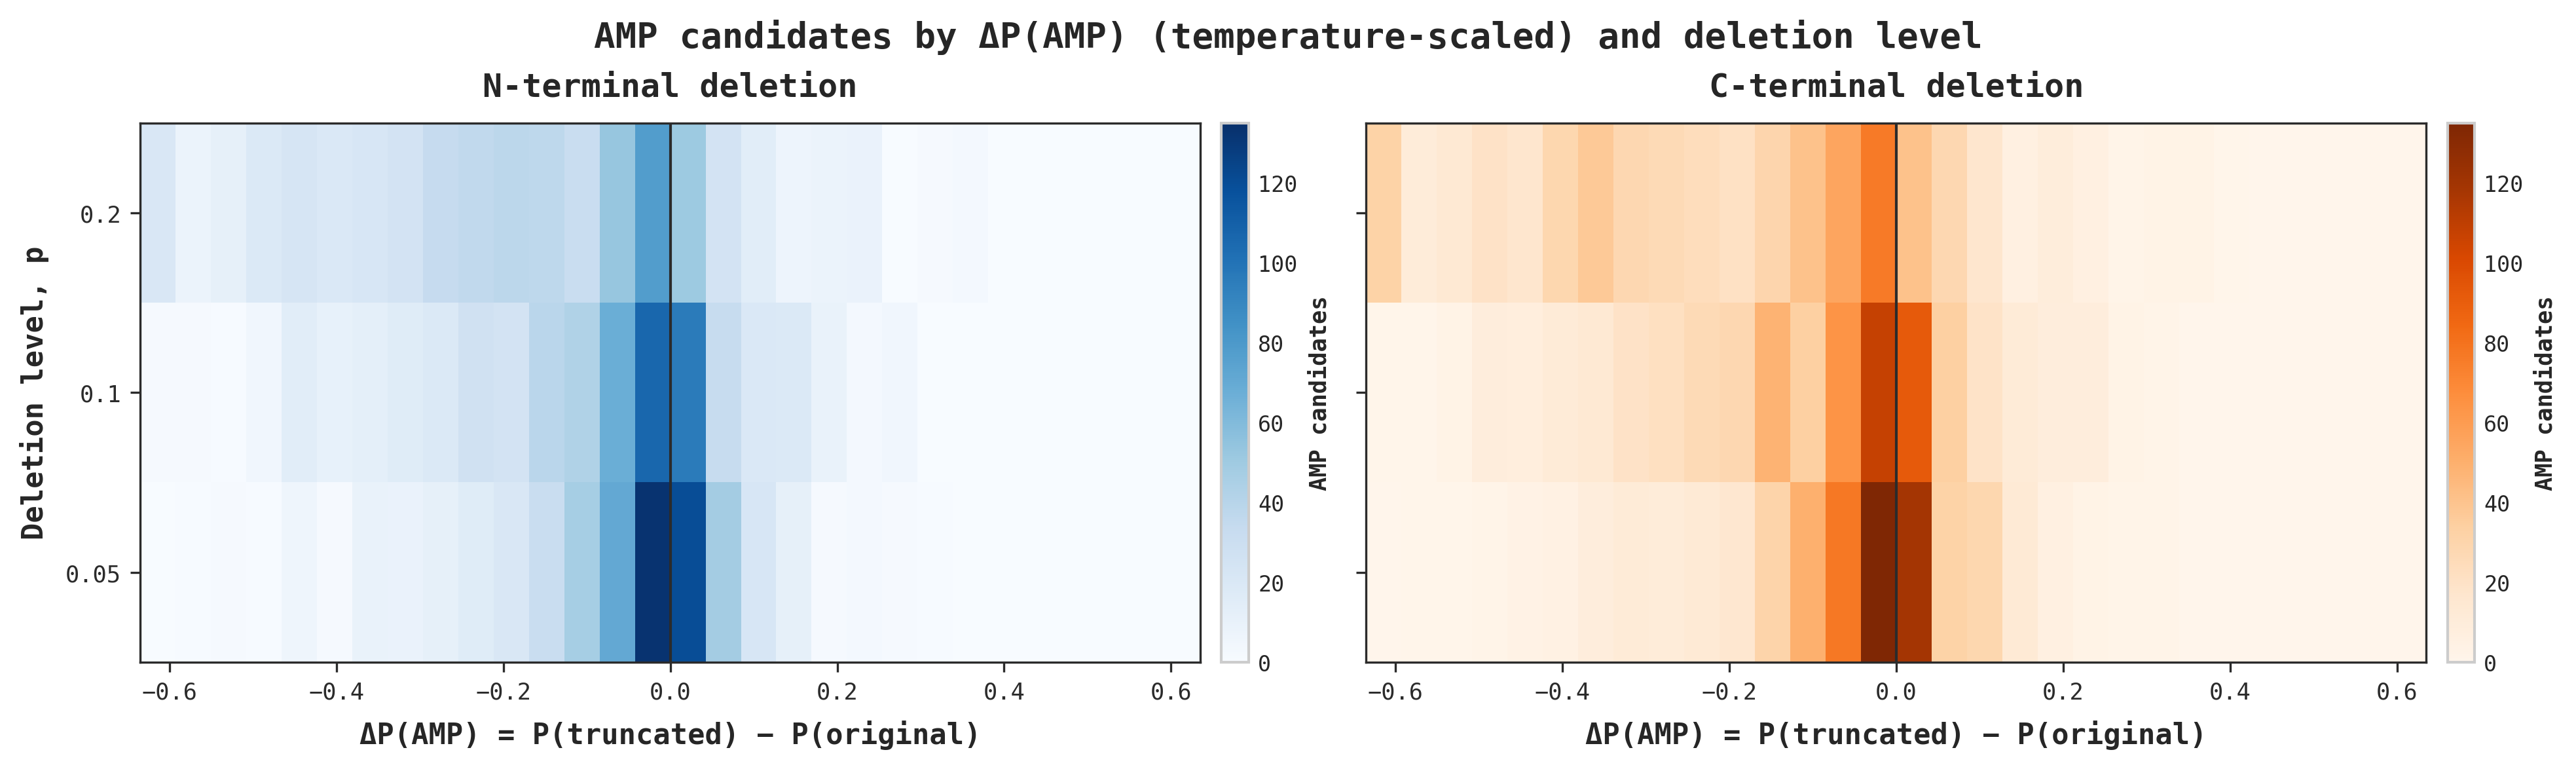

In [3]:
def symmetric_edges(values: pd.Series, bins: int = 30, percentile: float = 99.0) -> np.ndarray:
    span = float(np.nanpercentile(np.abs(values), percentile))
    return np.linspace(-span, span, bins + 1)


def deletion_heatmap(frame: pd.DataFrame, value: str, value_label: str, title: str) -> None:
    """Counts of AMP candidates per (delta bin, p) cell, one panel per terminus."""
    edges = symmetric_edges(frame[value])
    grids = {
        terminus: np.vstack([
            np.histogram(
                frame.loc[(frame["terminus"] == terminus) & (frame["p"] == level), value]
                .clip(edges[0], edges[-1]),
                bins=edges,
            )[0]
            for level in P_LEVELS
        ])
        for terminus in TERMINUS_ORDER
    }
    peak = max(int(grid.max()) for grid in grids.values())

    figure, axes = plt.subplots(1, len(TERMINUS_ORDER), figsize=(13.0, 3.8), dpi=300,
                               sharey=True, layout="constrained")
    for axis, terminus in zip(axes, TERMINUS_ORDER):
        mesh = axis.pcolormesh(edges, np.arange(len(P_LEVELS) + 1), grids[terminus],
                               cmap=TERMINUS_CMAP[terminus], vmin=0, vmax=peak)
        axis.axvline(0.0, color=SPINE_COLOR, linewidth=1.0)
        axis.set_yticks(np.arange(len(P_LEVELS)) + 0.5)
        axis.set_yticklabels([f"{level:g}" for level in P_LEVELS])
        axis.set_title(TERMINUS_LABEL[terminus], fontsize=TITLE_SIZE, fontweight="bold", pad=10)
        axis.set_xlabel(value_label, fontsize=LABEL_SIZE, fontweight="bold", labelpad=6)
        axis.grid(False)
        axis.tick_params(axis="both", labelsize=8.5, length=3.5, width=0.8, colors=SPINE_COLOR)
        for side in ("top", "right", "left", "bottom"):
            axis.spines[side].set_visible(True)
            axis.spines[side].set_color(SPINE_COLOR)
            axis.spines[side].set_linewidth(0.8)
        bar = figure.colorbar(mesh, ax=axis, pad=0.02)
        bar.set_label("AMP candidates", fontsize=8.5, fontweight="bold")
        bar.ax.tick_params(labelsize=8)

    axes[0].set_ylabel("Deletion level, p", fontsize=LABEL_SIZE, fontweight="bold", labelpad=6)
    figure.suptitle(title, fontsize=TITLE_SIZE + 1, fontweight="bold")
    plt.show()


deletion_heatmap(
    amp_curves,
    "delta_sigma",
    "Δσ = σ(truncated) − σ(original)",
    "AMP candidates by Δσ (raw logit difference) and deletion level",
)
deletion_heatmap(
    amp_curves,
    "delta_prob_AMP",
    "ΔP(AMP) = P(truncated) − P(original)",
    "AMP candidates by ΔP(AMP) (temperature-scaled) and deletion level",
)

## Δ versus p for AMP candidates (σ > 0)

One panel per terminus. Faint lines are individual peptides; the bold line is the mean across them
with a 95% confidence interval. Both Δσ and ΔP(AMP) are plotted, as in `mutation_analysis.ipynb`.

Peptides with no p = 0.05 variant (k would round to 0) leave a gap at that level rather than
being dropped from the panel.

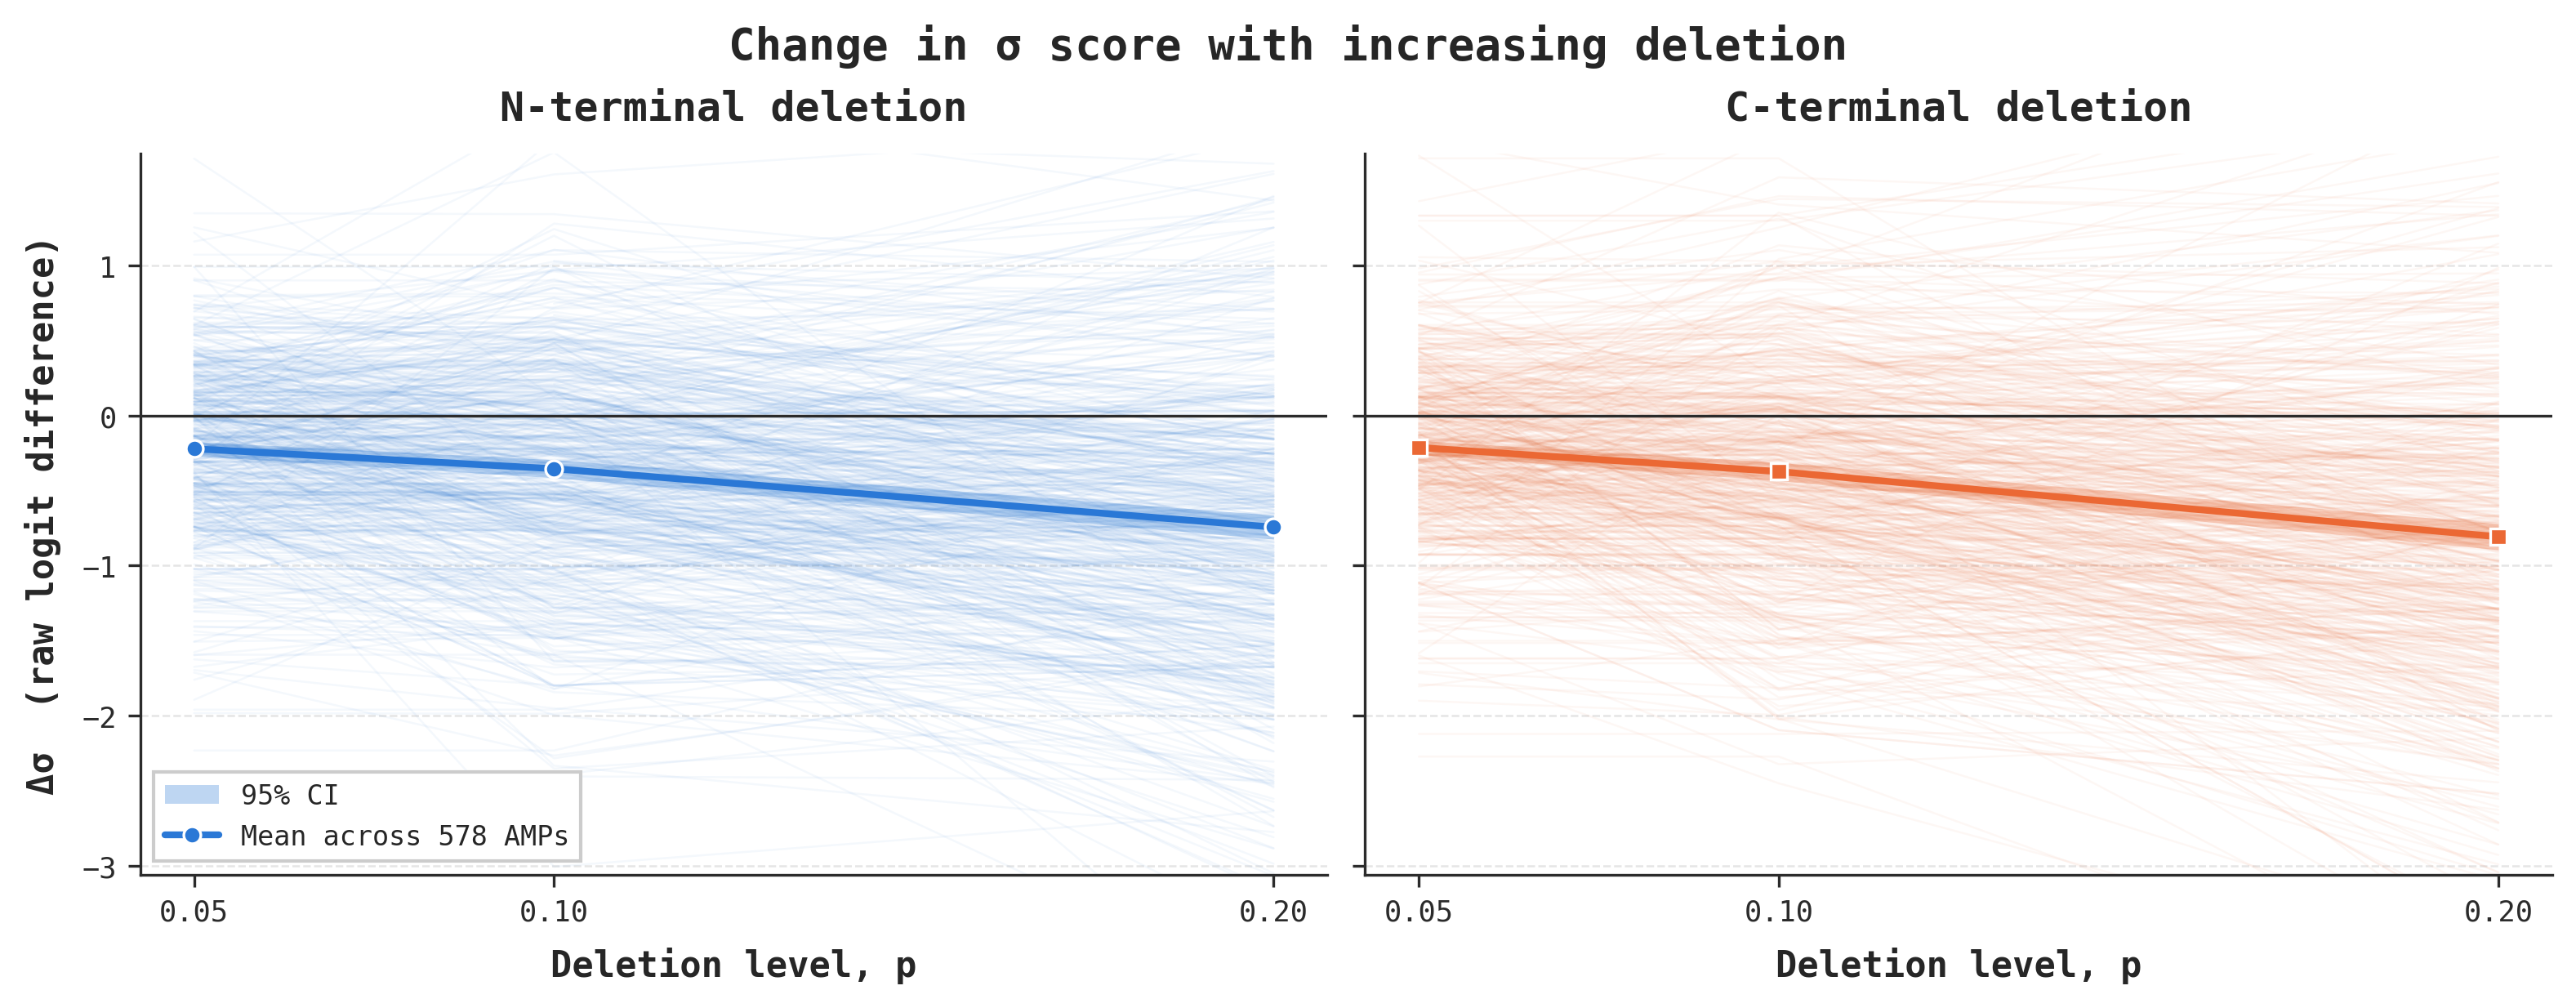

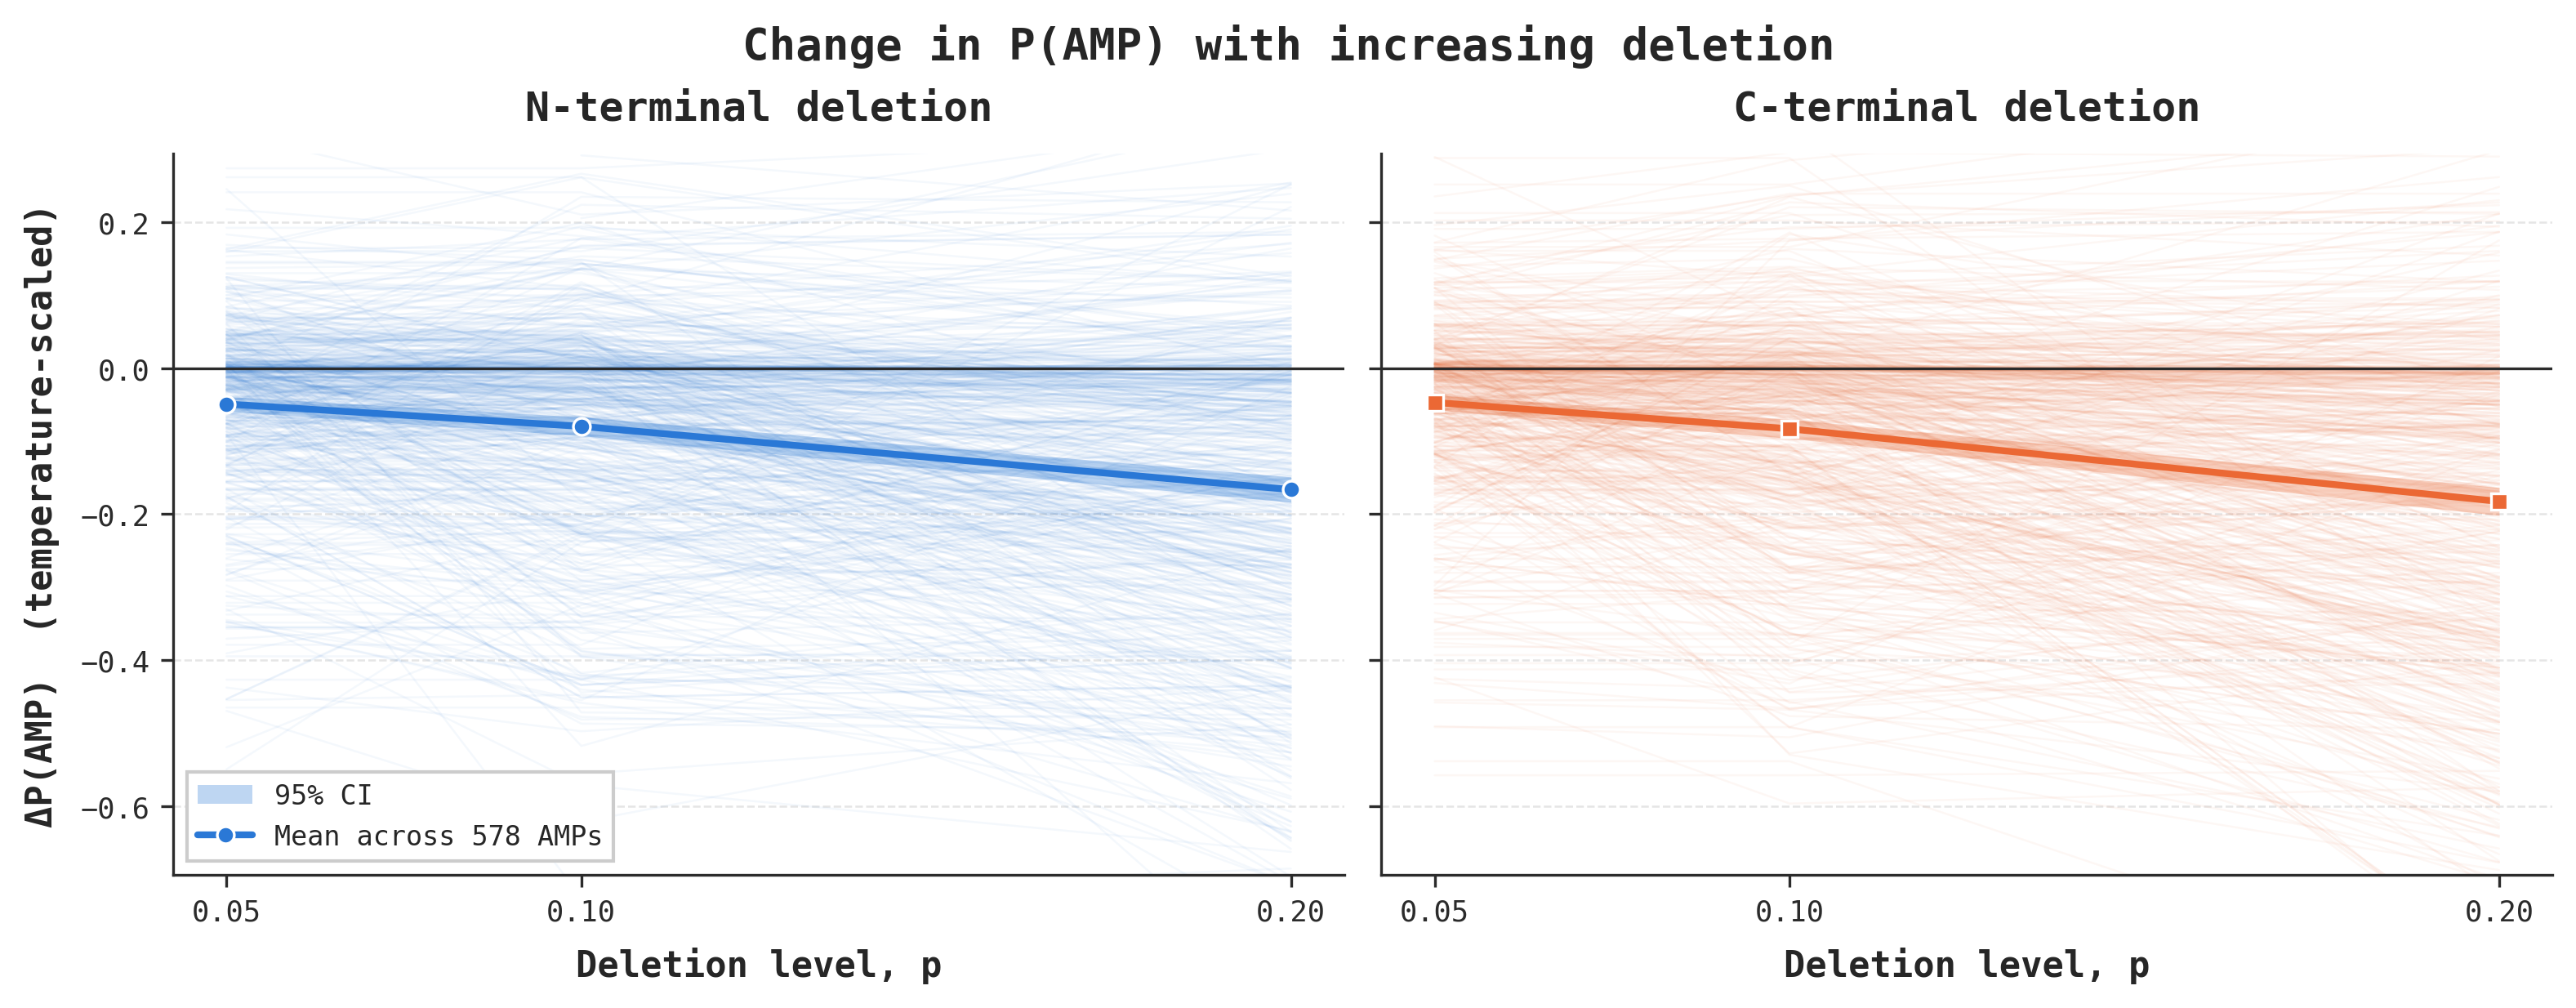

In [4]:
def mean_ci(frame: pd.DataFrame, value: str) -> pd.DataFrame:
    """Per-p mean across parents with a normal-approximation 95% CI."""
    stats = frame.groupby("p")[value].agg(["mean", "std", "count"])
    half_width = 1.96 * stats["std"] / np.sqrt(stats["count"])
    stats["low"] = stats["mean"] - half_width
    stats["high"] = stats["mean"] + half_width
    return stats.reset_index()


def plot_delta_vs_p(frame: pd.DataFrame, value: str, y_label: str, title: str) -> None:
    figure, axes = plt.subplots(1, len(TERMINUS_ORDER), figsize=(10.4, 4.0), dpi=300,
                               sharey=True, layout="constrained")
    for axis, terminus in zip(axes, TERMINUS_ORDER):
        subset = frame[frame["terminus"] == terminus]
        color = TERMINUS_COLOR[terminus]

        spaghetti = subset.pivot(index="p", columns="parent_id", values=value)
        axis.plot(spaghetti.index, spaghetti.to_numpy(), color=color, alpha=0.05, linewidth=0.6)

        stats = mean_ci(subset, value)
        axis.fill_between(stats["p"], stats["low"], stats["high"], color=color, alpha=0.3,
                          linewidth=0, label="95% CI")
        axis.plot(stats["p"], stats["mean"], color=color, linewidth=2.0,
                  marker=TERMINUS_MARKER[terminus], markersize=5, markeredgecolor="white",
                  markeredgewidth=0.8, label=f"Mean across {subset['parent_id'].nunique():,} AMPs")

        axis.axhline(0.0, color=SPINE_COLOR, linewidth=0.8)
        axis.set_title(TERMINUS_LABEL[terminus], fontsize=TITLE_SIZE, fontweight="bold", pad=10)
        axis.set_xlabel("Deletion level, p", fontsize=LABEL_SIZE, fontweight="bold", labelpad=6)
        axis.set_xticks(P_LEVELS)
        style_axes(axis)

    # Clip to the bulk so the means stay legible; a few peptides run far past this.
    low, high = np.nanpercentile(frame[value], [0.5, 99.5])
    axes[0].set_ylim(low, high)
    axes[0].set_ylabel(y_label, fontsize=LABEL_SIZE, fontweight="bold", labelpad=6)
    axes[0].legend(loc="lower left", fontsize=8, frameon=True, fancybox=False, framealpha=1)
    figure.suptitle(title, fontsize=TITLE_SIZE + 1, fontweight="bold")
    plt.show()


plot_delta_vs_p(
    amp_curves,
    "delta_sigma",
    "Δσ  (raw logit difference)",
    "Change in σ score with increasing deletion",
)
plot_delta_vs_p(
    amp_curves,
    "delta_prob_AMP",
    "ΔP(AMP)  (temperature-scaled)",
    "Change in P(AMP) with increasing deletion",
)

## AMP call retention versus p

The fraction of the σ > 0 candidates still called AMP after truncation. Deletion is deterministic,
so retention here is a fraction *across peptides* at each (terminus, p) — not across replicates of
one peptide, as it is in the mutation sweep.

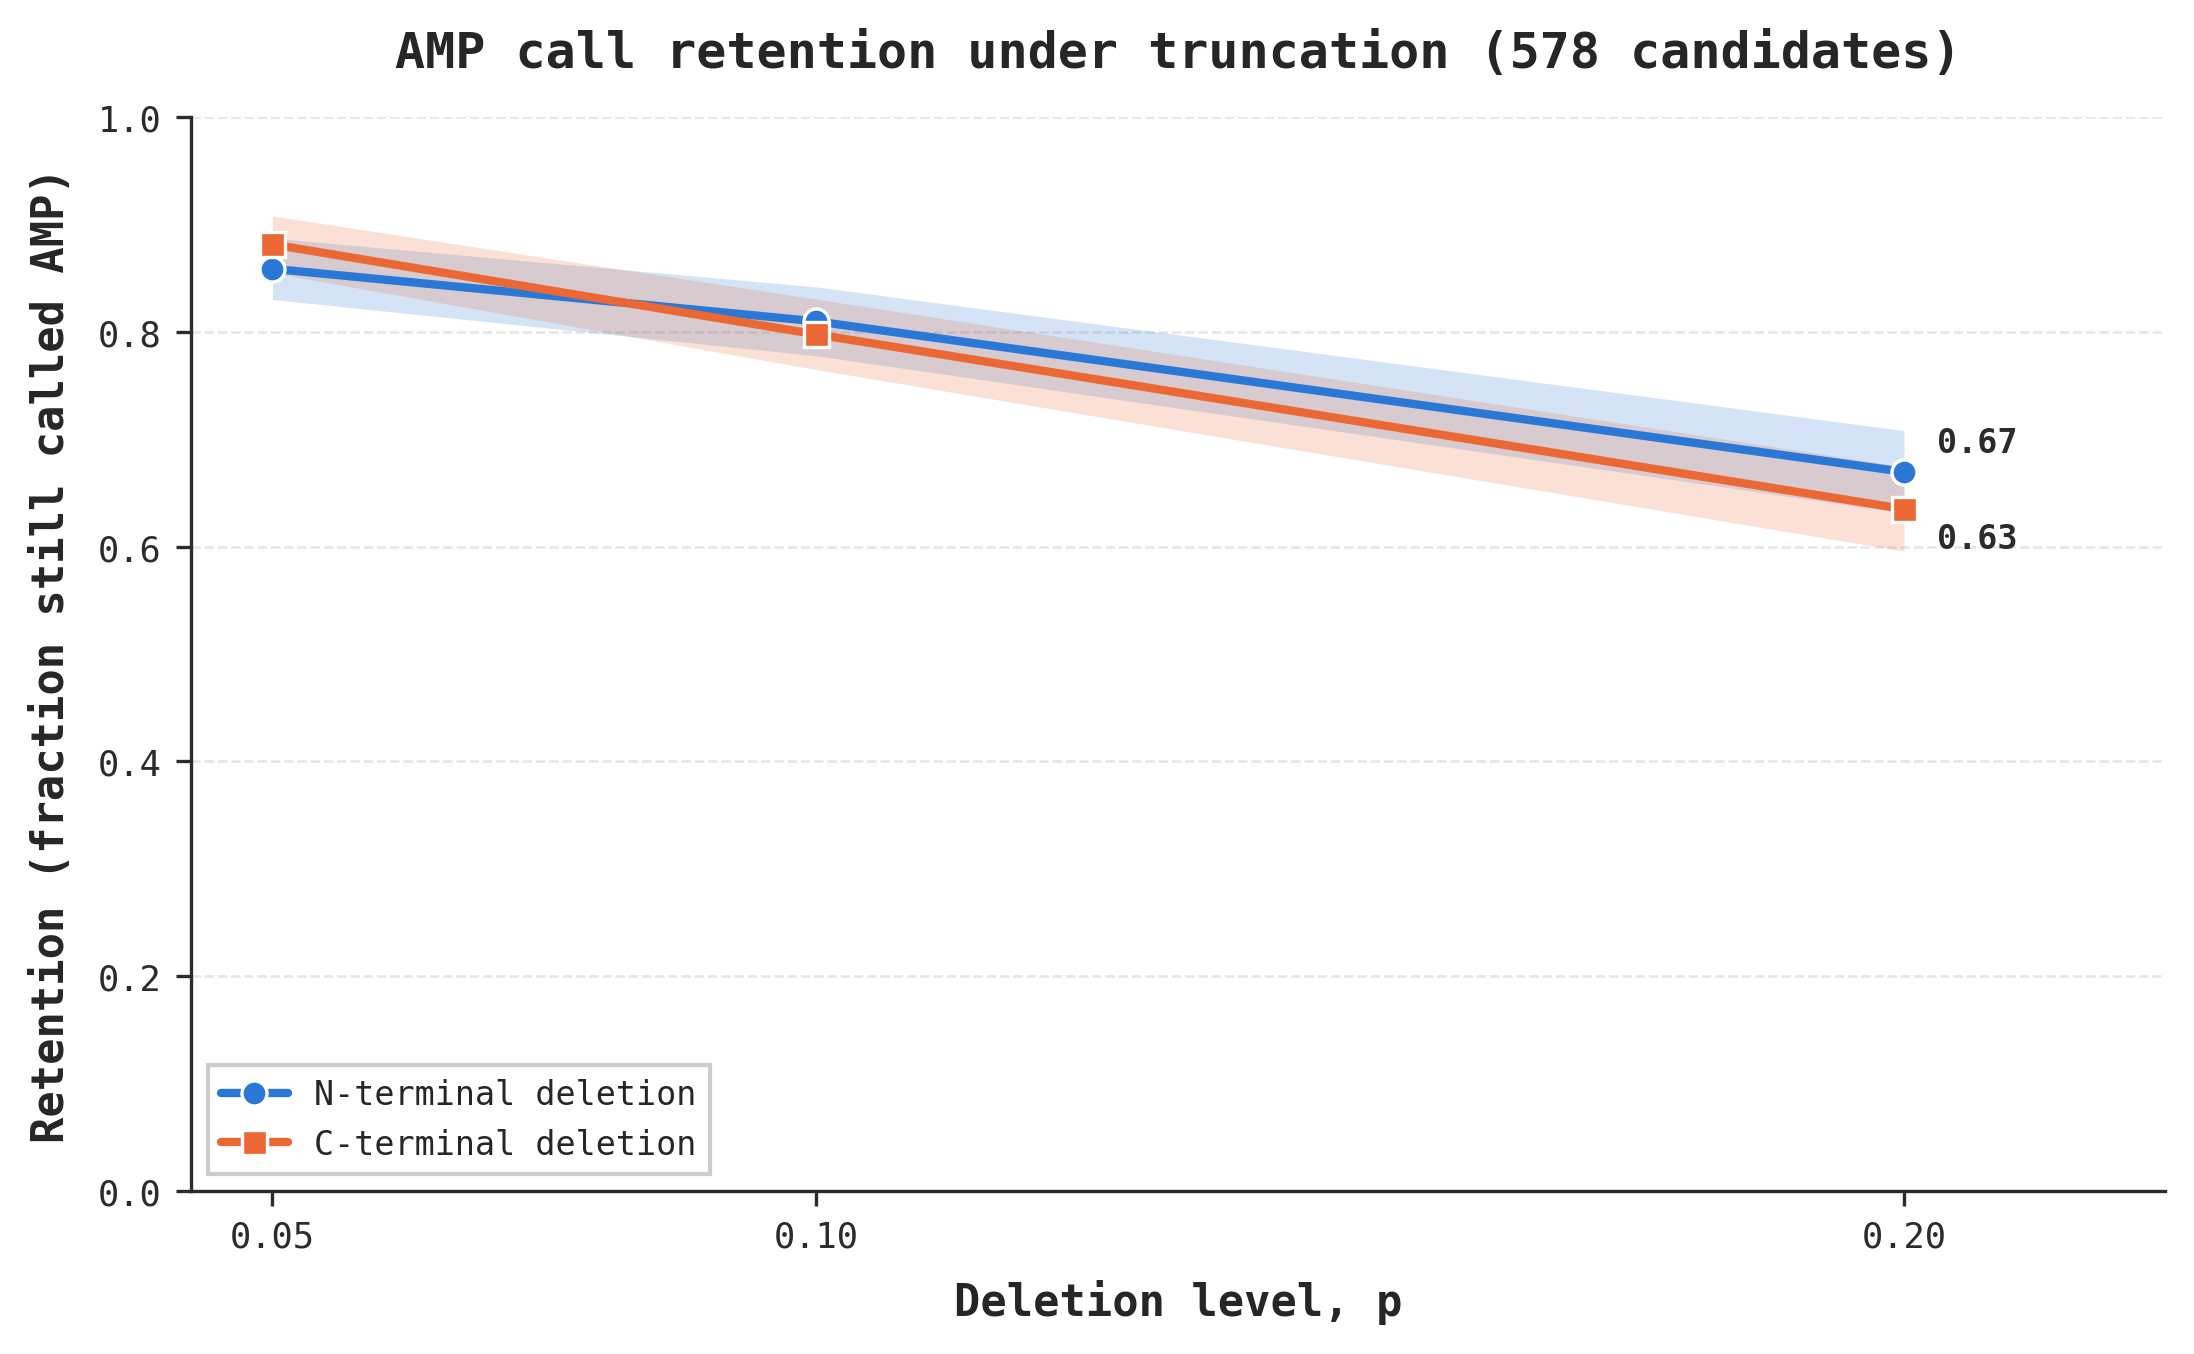

In [5]:
LABEL_OFFSET = {"N": 7.0, "C": -7.0}

figure, axis = plt.subplots(figsize=(7.2, 4.4), dpi=300, layout="constrained")
for terminus in TERMINUS_ORDER:
    stats = mean_ci(amp_curves[amp_curves["terminus"] == terminus], "called_AMP")
    color = TERMINUS_COLOR[terminus]
    axis.fill_between(stats["p"], stats["low"], stats["high"], color=color, alpha=0.2, linewidth=0)
    axis.plot(stats["p"], stats["mean"], color=color, linewidth=2.0,
              marker=TERMINUS_MARKER[terminus], markersize=6, markeredgecolor="white",
              markeredgewidth=0.8, label=TERMINUS_LABEL[terminus])
    axis.annotate(f"{stats['mean'].iloc[-1]:.2f}", (stats["p"].iloc[-1], stats["mean"].iloc[-1]),
                  textcoords="offset points", xytext=(8, LABEL_OFFSET[terminus]),
                  color=SPINE_COLOR, fontsize=8, fontweight="bold", va="center")

axis.set_xlabel("Deletion level, p", fontsize=LABEL_SIZE, fontweight="bold", labelpad=6)
axis.set_ylabel("Retention (fraction still called AMP)", fontsize=LABEL_SIZE,
                fontweight="bold", labelpad=6)
axis.set_xticks(P_LEVELS)
axis.set_xlim(right=max(P_LEVELS) * 1.12)
axis.set_ylim(0, 1)
axis.legend(loc="lower left", fontsize=8, frameon=True, fancybox=False, framealpha=1)
axis.set_title(f"AMP call retention under truncation ({amp_curves['parent_id'].nunique():,} candidates)",
               fontsize=TITLE_SIZE, fontweight="bold", pad=12)
style_axes(axis)
plt.show()

In [6]:
summary = (
    amp_curves.groupby(["terminus", "p"])
    .agg(
        candidates=("parent_id", "nunique"),
        mean_k=("k", "mean"),
        mean_delta_sigma=("delta_sigma", "mean"),
        mean_delta_prob_AMP=("delta_prob_AMP", "mean"),
        retention=("called_AMP", "mean"),
    )
    .reset_index()
)
display(summary.style.format({
    "p": "{:g}", "mean_k": "{:.2f}", "mean_delta_sigma": "{:+.3f}",
    "mean_delta_prob_AMP": "{:+.3f}", "retention": "{:.3f}",
}).hide(axis="index"))

terminus,p,candidates,mean_k,mean_delta_sigma,mean_delta_prob_AMP,retention
C,0.05,573,1.09,-0.213,-0.047,0.881
C,0.1,578,2.00,-0.373,-0.083,0.798
C,0.2,578,3.92,-0.807,-0.183,0.635
N,0.05,573,1.09,-0.221,-0.049,0.859
N,0.1,578,2.00,-0.354,-0.080,0.810
N,0.2,578,3.92,-0.743,-0.166,0.670


## Caveat — truncation moves peptides along a confounded axis

The GNN's training positives are short peptides folded in isolation while its negatives are whole
protein chains folded whole, so graph size tracks class in the training data. Deletion shortens
peptides, which moves them *away* from the decoy-dominated length regime rather than toward it —
the opposite direction to the extension sweep — but any monotone length effect still rides on top
of the sequence effect being measured here. A length-matched control or y-randomization would be
needed before reading these curves as sequence-specific.